In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


df = pd.read_csv("reviews.csv")

print("Dataset shape:", df.shape)
print(df[["review_text", "rating", "sentiment"]].head())
print(df["sentiment"].value_counts())

Dataset shape: (147640, 10)
                                         review_text  rating sentiment
0  Granddaughters love them!. I purchased several...     5.0  positive
1  Arrived broken. It’s cute, but it arrived brok...     3.0   neutral
2  Dylan loves them!!!. Bough for my grandson Dyl...     5.0  positive
3  Janod quality and very cute.... This was great...     5.0  positive
4  I used for my daughters circus birthday party ...     3.0   neutral
sentiment
negative    49692
neutral     49477
positive    48471
Name: count, dtype: int64


In [2]:
%pip install -U scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [3]:
%pip install sentence_transformers

Note: you may need to restart the kernel to use updated packages.


In [18]:
# creating train and test splits

from sklearn.model_selection import train_test_split

X = df["review_text"].fillna("").astype(str)
y = df["sentiment"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

Train shape: (118112,)
Test shape: (29528,)


In [19]:
# create common model evaluation function

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

from sklearn.metrics import confusion_matrix

results = []

def evaluate_model(name, y_true, y_pred):
    accuracy = accuracy_score(y_true, y_pred)
    macro_f1 = f1_score(
        y_true, y_pred, average="macro", zero_division=0
    )
    weighted_f1 = f1_score(
        y_true, y_pred, average="weighted", zero_division=0
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Macro F1": macro_f1,
        "Weighted F1": weighted_f1
    })

    print(f"\n{name}")
    print("Accuracy:", round(accuracy, 4))
    print("Macro F1:", round(macro_f1, 4))
    print(classification_report(
        y_true,
        y_pred,
        labels=["negative", "neutral", "positive"],
        zero_division=0
    ))

    ConfusionMatrixDisplay.from_predictions(
        y_true,
        y_pred,
        labels=["negative", "neutral", "positive"],
        cmap = "Blues",
        xticks_rotation=45
    )
    plt.tight_layout()
    plt.show()

Textblob


TextBlob
Accuracy: 0.5009
Macro F1: 0.474
              precision    recall  f1-score   support

    negative       0.72      0.31      0.43      9938
     neutral       0.39      0.33      0.35      9896
    positive       0.50      0.88      0.64      9694

    accuracy                           0.50     29528
   macro avg       0.54      0.50      0.47     29528
weighted avg       0.54      0.50      0.47     29528



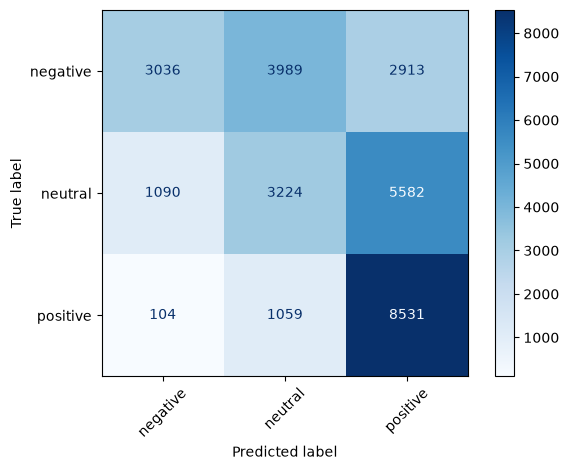

In [21]:
from textblob import TextBlob

def textblob_predict(text):
    polarity = TextBlob(text).sentiment.polarity

    if polarity < -0.1:
        return "negative"
    elif polarity > 0.1:
        return "positive"
    else:
        return "neutral"

textblob_pred = X_test.apply(textblob_predict)

evaluate_model("TextBlob", y_test, textblob_pred)

In [22]:
# Create a results table for textblob
results_example = pd.DataFrame({
    "Review": X_test,
    "Actual Sentiment (from Rating)": y_test
})

results_example["Polarity Score"] = results_example["Review"].apply(
    lambda text: TextBlob(text).sentiment.polarity
)

results_example["TextBlob Prediction"] = results_example["Review"].apply(
    textblob_predict
)

# Display 20 examples
display(results_example.head(20))

,Review,Actual Sentiment (from Rating),Polarity Score,TextBlob Prediction
86118,So sad these are defective. My kids wanted the...,negative,-0.058333,neutral
138492,so I can't really review it except to say she ...,neutral,0.450000,positive
113264,Cheap fabric. Definitely not what I was expect...,negative,0.306667,positive
119774,Not worth it. I bought this for my daughter's ...,negative,-0.168750,negative
22021,Perfect for the beach. My granddaughter loved ...,positive,0.433333,positive
120754,... holding on dress failed causing dress to f...,negative,-0.450000,negative
89434,Three Stars. Ok,neutral,0.500000,positive
74656,No color whatsoever.. Barely make a mark. No c...,negative,0.050000,neutral
99536,"her hair is awesome, of course. I got this for...",neutral,0.103030,positive
35205,Big hit!. Purchased for my 4 year old grandson...,positive,0.050000,neutral


TF-IDF and Logistic Regression


TF-IDF + Logistic Regression (unweighted)
Accuracy: 0.7883
Macro F1: 0.7891
              precision    recall  f1-score   support

    negative       0.79      0.78      0.78      9938
     neutral       0.70      0.70      0.70      9896
    positive       0.89      0.88      0.89      9694

    accuracy                           0.79     29528
   macro avg       0.79      0.79      0.79     29528
weighted avg       0.79      0.79      0.79     29528



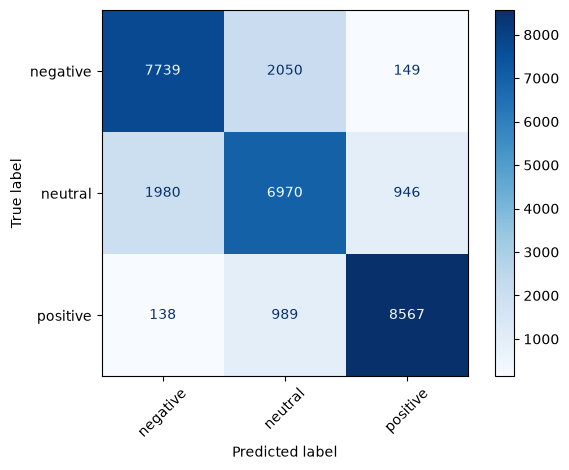

In [ ]:
# no class balancing
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

def make_lr(class_weight=None):
    return Pipeline([
        ("tfidf", TfidfVectorizer(
            max_features=50000,
            ngram_range=(1, 2),
            min_df=2
        )),
        ("classifier", LogisticRegression(
            max_iter=1000,
            class_weight=class_weight,
            random_state=42
        ))
    ])

# No class balancing
lr_normal = make_lr()
lr_normal.fit(X_train, y_train)
lr_normal_pred = lr_normal.predict(X_test)

evaluate_model(
    "TF-IDF + Logistic Regression (unweighted)",
    y_test, lr_normal_pred
)


TF-IDF + Logistic Regression (balanced)
Accuracy: 0.8923
Macro F1: 0.6722
              precision    recall  f1-score   support

    negative       0.58      0.71      0.64       236
     neutral       0.34      0.57      0.42       218
    positive       0.98      0.92      0.95      3465

    accuracy                           0.89      3919
   macro avg       0.63      0.74      0.67      3919
weighted avg       0.92      0.89      0.90      3919



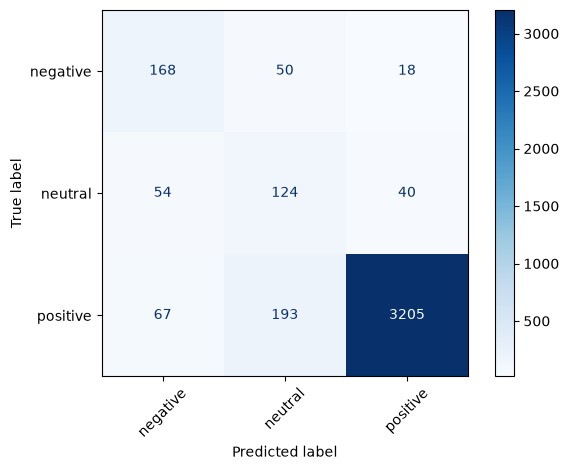

In [ ]:
# NOT NEEDED SINCE THE DATA IS ALR BALANCED

# Class-weighted

"""
lr_balanced = make_lr(class_weight="balanced")
lr_balanced.fit(X_train, y_train)
lr_balanced_pred = lr_balanced.predict(X_test)

evaluate_model(
    "TF-IDF + Logistic Regression (balanced)",
    y_test, lr_balanced_pred
)

"""

TF-IDF and Random Forest


TF-IDF + Random Forest (unweighted)
Accuracy: 0.7549
Macro F1: 0.7541
              precision    recall  f1-score   support

    negative       0.75      0.76      0.76      9938
     neutral       0.68      0.64      0.66      9896
    positive       0.83      0.87      0.85      9694

    accuracy                           0.75     29528
   macro avg       0.75      0.76      0.75     29528
weighted avg       0.75      0.75      0.75     29528



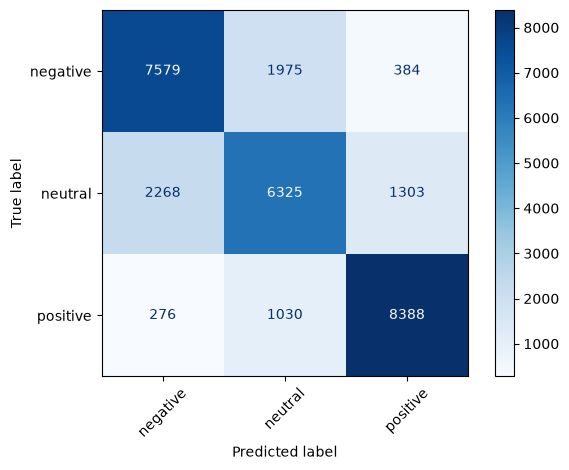

In [24]:
# no class balancing

from sklearn.ensemble import RandomForestClassifier

def make_rf(class_weight=None):
    return Pipeline([
        ("tfidf", TfidfVectorizer(
            max_features=30000,
            ngram_range=(1, 2),
            min_df=2
        )),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            class_weight=class_weight,
            random_state=42,
            n_jobs=-1
        ))
    ])

# Unweighted
rf_normal = make_rf()
rf_normal.fit(X_train, y_train)
rf_normal_pred = rf_normal.predict(X_test)

evaluate_model(
    "TF-IDF + Random Forest (unweighted)",
    y_test, rf_normal_pred
)



TF-IDF + Random Forest (balanced)
Accuracy: 0.9061
Macro F1: 0.5471
              precision    recall  f1-score   support

    negative       0.77      0.44      0.56       236
     neutral       0.46      0.08      0.13       218
    positive       0.92      0.99      0.95      3465

    accuracy                           0.91      3919
   macro avg       0.71      0.50      0.55      3919
weighted avg       0.88      0.91      0.88      3919



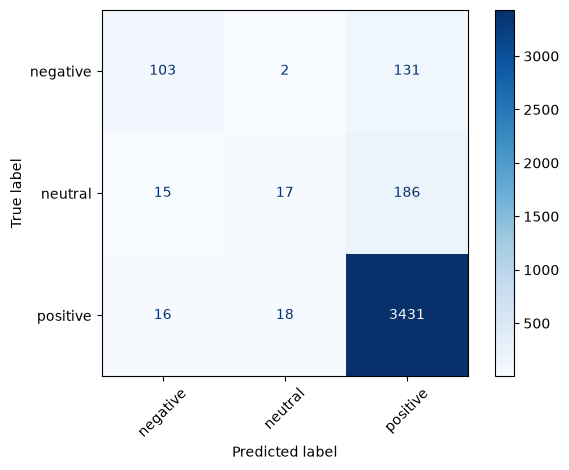

In [ ]:

# comment out classes alr balanced

"""
# Balanced
rf_balanced = make_rf(class_weight="balanced")
rf_balanced.fit(X_train, y_train)
rf_balanced_pred = rf_balanced.predict(X_test)

evaluate_model(
    "TF-IDF + Random Forest (balanced)",
    y_test, rf_balanced_pred
)
"""

BERT + LR

c:\Users\ikhta\.anaconda-desktop\micromamba\envs\assistant\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Batches: 100%|██████████| 923/923 [03:21<00:00,  4.58it/s]



BERT embeddings + Logistic Regression (unweighted)
Accuracy: 0.7339
Macro F1: 0.7336
              precision    recall  f1-score   support

    negative       0.73      0.74      0.73      9938
     neutral       0.64      0.62      0.63      9896
    positive       0.83      0.85      0.84      9694

    accuracy                           0.73     29528
   macro avg       0.73      0.73      0.73     29528
weighted avg       0.73      0.73      0.73     29528



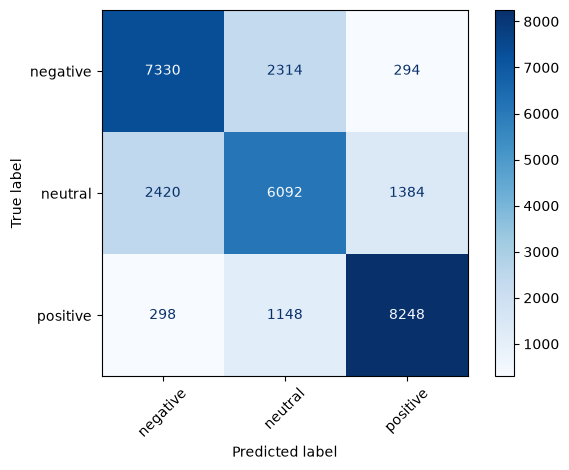

In [25]:
from sentence_transformers import SentenceTransformer
from sklearn.linear_model import LogisticRegression

embedding_model = SentenceTransformer("all-MiniLM-L6-v2")

X_train_emb = embedding_model.encode(
    X_train.tolist(),
    show_progress_bar=True,
    batch_size=32
)

X_test_emb = embedding_model.encode(
    X_test.tolist(),
    show_progress_bar=True,
    batch_size=32
)

# Unweighted classifier
bert_lr_normal = LogisticRegression(
    max_iter=1000,
    random_state=42
)
bert_lr_normal.fit(X_train_emb, y_train)

bert_normal_pred = bert_lr_normal.predict(X_test_emb)

evaluate_model(
    "BERT embeddings + Logistic Regression (unweighted)",
    y_test, bert_normal_pred
)



BERT embeddings + Logistic Regression (balanced)
Accuracy: 0.8163
Macro F1: 0.591
              precision    recall  f1-score   support

    negative       0.48      0.71      0.57       236
     neutral       0.20      0.56      0.29       218
    positive       0.98      0.84      0.91      3465

    accuracy                           0.82      3919
   macro avg       0.55      0.70      0.59      3919
weighted avg       0.91      0.82      0.85      3919



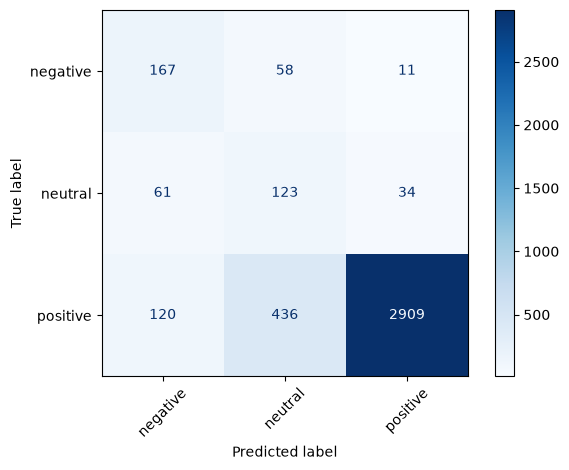

In [ ]:
# not needed since the data is already balanced

"""

# Balanced classifier
bert_lr_balanced = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)
bert_lr_balanced.fit(X_train_emb, y_train)

bert_balanced_pred = bert_lr_balanced.predict(X_test_emb)

evaluate_model(
    "BERT embeddings + Logistic Regression (balanced)",
    y_test, bert_balanced_pred
)

"""

Transformer

In [26]:
%pip install transformers

Note: you may need to restart the kernel to use updated packages.


In [27]:
from transformers import pipeline

transformer = pipeline(
    "sentiment-analysis",
    model="cardiffnlp/twitter-roberta-base-sentiment-latest",
    truncation=True
)


Loading weights: 100%|██████████| 201/201 [00:00<00:00, 26295.35it/s]
[transformers] RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base-sentiment-latest
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.bias   | UNEXPECTED |  | 
roberta.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


{'negative', 'neutral', 'positive'}

Pretrained transformer
Accuracy: 0.6587
Macro F1: 0.6058
              precision    recall  f1-score   support

    negative       0.64      0.84      0.73      9938
     neutral       0.61      0.19      0.29      9896
    positive       0.69      0.94      0.80      9694

    accuracy                           0.66     29528
   macro avg       0.65      0.66      0.61     29528
weighted avg       0.64      0.66      0.60     29528



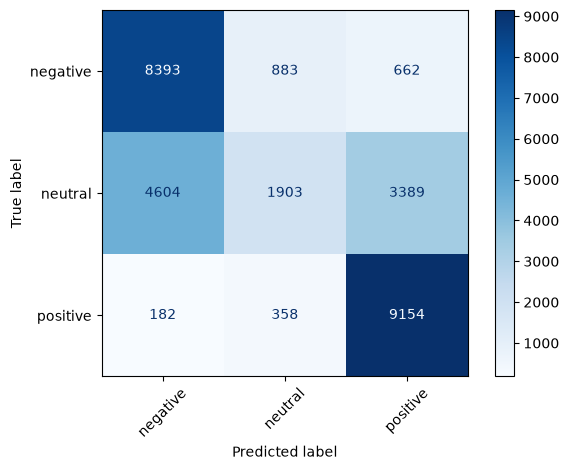

In [28]:

# Run sentiment analysis on the test reviews
transformer_outputs = transformer(
    X_test.fillna("").astype(str).tolist(),
    batch_size=16,
    truncation=True,
    max_length=512
)

# Map model labels to sentiment classes
label_map = {
    "label_0": "negative",
    "label_1": "neutral",
    "label_2": "positive",
    "negative": "negative",
    "neutral": "neutral",
    "positive": "positive"
}

print(set(result["label"] for result in transformer_outputs))

transformer_pred = [
    label_map[result["label"].lower()]
    for result in transformer_outputs
]

# Evaluate the model
evaluate_model(
    "Pretrained transformer",
    y_test,
    transformer_pred
)


Final results

In [29]:
results_df = pd.DataFrame(results)

display(results_df.sort_values(by="Macro F1", ascending=False).reset_index(drop=True))

,Model,Accuracy,Macro F1,Weighted F1
0,TF-IDF + Logistic Regression (unweighted),0.788269,0.789148,0.788481
1,TF-IDF + Random Forest (unweighted),0.754944,0.754053,0.753409
2,BERT embeddings + Logistic Regression (unweigh...,0.733880,0.733572,0.732838
3,Pretrained transformer,0.658697,0.605838,0.604684
4,TextBlob,0.500914,0.474010,0.472819
5,TextBlob,0.500914,0.474010,0.472819


Final model

In [30]:
import joblib

# Save the trained pipeline, including its TF-IDF vectorizer
joblib.dump(lr_normal, "sentiment_model.joblib")

# Load your complete processed dataset
df = pd.read_csv("reviews.csv")

# Predict sentiment for all reviews
df["predicted_sentiment"] = lr_normal.predict(
    df["review_text"].fillna("").astype(str)
)

# Get the highest predicted class probability
probabilities = lr_normal.predict_proba(
    df["review_text"].fillna("").astype(str)
)
df["prediction_confidence"] = probabilities.max(axis=1)

# Compare with rating-derived sentiment
df["rating_sentiment"] = df["sentiment"]
df["sentiment_disagreement"] = (
    df["predicted_sentiment"] != df["rating_sentiment"]
)

df.to_csv("reviews_with_predictions.csv", index=False)

print("Saved model and predictions.")
display(df[[
    "rating", "review_text", "predicted_sentiment",
    "prediction_confidence", "sentiment_disagreement"
]].head())

Saved model and predictions.


,rating,review_text,predicted_sentiment,prediction_confidence,sentiment_disagreement
0,5.0,Granddaughters love them!. I purchased several...,positive,0.523580,False
1,3.0,"Arrived broken. It’s cute, but it arrived brok...",neutral,0.719123,False
2,5.0,Dylan loves them!!!. Bough for my grandson Dyl...,positive,0.957095,False
3,5.0,Janod quality and very cute.... This was great...,positive,0.954691,False
4,3.0,I used for my daughters circus birthday party ...,neutral,0.710843,False


In [35]:
df.head()

,rating,title,text,parent_asin,timestamp,helpful_vote,verified_purchase,user_id,review_text,sentiment,predicted_sentiment,prediction_confidence,rating_sentiment,sentiment_disagreement
0,5.0,Granddaughters love them!,I purchased several of these for my granddaugh...,B09QH7QJS7,1970-01-01 00:27:57.939664713,0,True,AFKZENTNBQ7A7V7UXW5JJI6UGRYQ,Granddaughters love them!. I purchased several...,positive,positive,0.523580,positive,False
1,3.0,Arrived broken,"It’s cute, but it arrived broken & has some pr...",B06XYKSKQP,1970-01-01 00:27:19.855230760,1,True,AFKZENTNBQ7A7V7UXW5JJI6UGRYQ,"Arrived broken. It’s cute, but it arrived brok...",neutral,neutral,0.719123,neutral,False
2,5.0,Dylan loves them!!!,Bough for my grandson Dylan. He loves them.,B07XRSD5R9,1970-01-01 00:26:20.949719154,0,True,AFKZENTNBQ7A7V7UXW5JJI6UGRYQ,Dylan loves them!!!. Bough for my grandson Dyl...,positive,positive,0.957095,positive,False
3,5.0,Janod quality and very cute...,This was great for my daughters circus themed ...,B007JWWUDW,1970-01-01 00:24:31.542588000,0,True,AGKASBHYZPGTEPO6LWZPVJWB2BVA,Janod quality and very cute.... This was great...,positive,positive,0.954691,positive,False
4,3.0,I used for my daughters circus birthday party ...,This is very cute but beware that the animals ...,B00MZG6OO8,1970-01-01 00:24:31.541996000,2,True,AGKASBHYZPGTEPO6LWZPVJWB2BVA,I used for my daughters circus birthday party ...,neutral,neutral,0.710843,neutral,False
